# Transcript Analysis Helper

Interactively explore the transcript `.txt` files housed under `data/` using the helpers defined in `script.py`.


In [240]:
from pathlib import Path

import pandas as pd

from dataloader import TranscriptLoader

loader = TranscriptLoader()
print(f"Data directory: {loader.data_dir}")


Data directory: /Users/bentindal/Desktop/CognoSpeak/data


In [241]:
from file_validator import validate_file_naming, print_validation_report

# Check for files that don't follow naming convention
naming_issues = validate_file_naming(Path(loader.data_dir))
print_validation_report(naming_issues)


FILE NAMING CONVENTION CHECK

Accepted formats:
  - Process-XXX__PFT.txt or Process-XXX__SFT.txt (double underscore)
  - Process-XXX_PFT.txt or Process-XXX_SFT.txt (single underscore)
Files should be in directories: Process-rec-XXX/ or Process-test-XXX/

✅ All files follow the naming convention!


In [242]:
transcript_paths = loader.discover_transcript_files()
len(transcript_paths), transcript_paths[:5]


(177,
 [PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-004/Process-rec-004__PFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-004/Process-rec-004__SFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-006/Process-rec-006_PFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-006/Process-rec-006_SFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-009/Process-rec-009__PFT.txt')])

In [243]:
example_path = transcript_paths[0]
example_df = loader.load_transcript(example_path)
example_df.head()


,start_time,end_time,token,recording,task,recording_number,source_path
0,0.445333,0.445333,plank,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
1,2.099429,2.099429,pool,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
2,4.835048,4.835048,pool,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
3,8.270476,8.270476,plethora,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
4,9.924571,9.924571,puzzle,Process-rec-004,PFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...


In [244]:
frames = loader.load_all_transcripts(transcript_paths)
combined = loader.concatenate_transcripts(frames.values())
summary = loader.summarize_structure(combined)
summary.to_frame(name='value')


,value
rows,3227
recordings,88
tasks,"PFT, SFT"
start_time_range,"(0.0, 62.605016)"
end_time_range,"(0.0, 62.690496)"
missing_values,0


In [245]:
metadata = loader.load_metadata()
metadata.head()


,recording,age,gender,diagnosis,MMSE,annotator,notes,recording_number
0,Process-rec-143,70.0,male,DEMENTIA,24.0,Madhu,"SFT: all good, something said at the end, can'...",143
1,Process-rec-091,73.0,female,DEMENTIA,20.0,Kevin,"SFT: good, repeated a couple words towards the...",91
2,Process-test-038,73.0,male,DEMENTIA,<NA>,Kevin,"SFT: good until end, noticeable pauses; PFT: n...",38
3,Process-rec-107,75.0,female,DEMENTIA,<NA>,Kevin,"SFT: good, noticeable pauses, repeated word; P...",107
4,Process-rec-040,77.0,male,DEMENTIA,<NA>,Kevin,"SFT: all good; PFT: poor, apologised for strug...",40


In [246]:
merged = loader.merge_with_metadata(combined, metadata)
merged[['recording', 'diagnosis']].drop_duplicates().head()


,recording,diagnosis
0,Process-rec-004,MCI
41,Process-rec-006,DEMENTIA
69,Process-rec-009,HC
116,Process-rec-010,HC
159,Process-rec-013,MCI


In [247]:
# Optional: persist the combined dataset for downstream work
output_path = Path('combined_transcripts.parquet')
combined.to_parquet(output_path, index=False)
output_path


PosixPath('combined_transcripts.parquet')

In [248]:
from pathlib import Path
from pause_analyzer import analyze_pauses

# Generate pause_summary.csv if it doesn't exist
pause_summary_path = Path('pause_summary.csv')
if not pause_summary_path.exists():
    print("Generating pause_summary.csv...")
    analyze_pauses(Path(loader.data_dir), pause_summary_path)
    print(f"✓ Created {pause_summary_path}")
else:
    print(f"✓ {pause_summary_path} already exists")


Generating pause_summary.csv...
✓ Created pause_summary.csv


## Pause Metrics by Diagnosis

Merge the pause statistics from `pause_summary.csv` with the subject metadata to compare cohorts (Dementia, MCI, HC).


In [249]:
import matplotlib.pyplot as plt
import seaborn as sns

pause_summary = pd.read_csv('pause_summary.csv')
pause_summary['recording'] = pause_summary['transcript'].str.split('/').str[0]

pause_with_diag = pause_summary.merge(
    metadata.rename(columns={'anyon_IDs': 'recording'})[['recording', 'diagnosis']],
    on='recording',
    how='left'
)
pause_with_diag.dropna(subset=['diagnosis'], inplace=True)
pause_with_diag.head()


,transcript,token_count,pause_count,pause_mean,pause_median,pause_min,pause_max,pause_std,pause_total,pause_q1,pause_q2,pause_q3,recording,diagnosis
0,Process-rec-004/Process-rec-004__PFT.txt,23,22,2.478251,1.972190,1.208762,7.697905,1.607948,54.521524,1.383714,1.972190,2.815143,Process-rec-004,MCI
1,Process-rec-004/Process-rec-004__SFT.txt,18,17,3.125438,2.160889,0.762667,13.028889,3.040823,53.132445,1.398222,2.160889,3.686222,Process-rec-004,MCI
2,Process-rec-006/Process-rec-006_PFT.txt,18,17,2.535626,1.223342,0.190297,13.555324,3.487955,43.105637,0.581923,1.223342,2.779910,Process-rec-006,DEMENTIA
3,Process-rec-006/Process-rec-006_SFT.txt,10,9,2.439959,1.364377,0.278641,8.438261,2.835415,21.959633,0.387204,1.364377,4.278873,Process-rec-006,DEMENTIA
4,Process-rec-009/Process-rec-009__PFT.txt,26,25,1.384587,1.034487,0.188424,5.889187,1.277464,34.614670,0.500618,1.034487,1.814047,Process-rec-009,HC


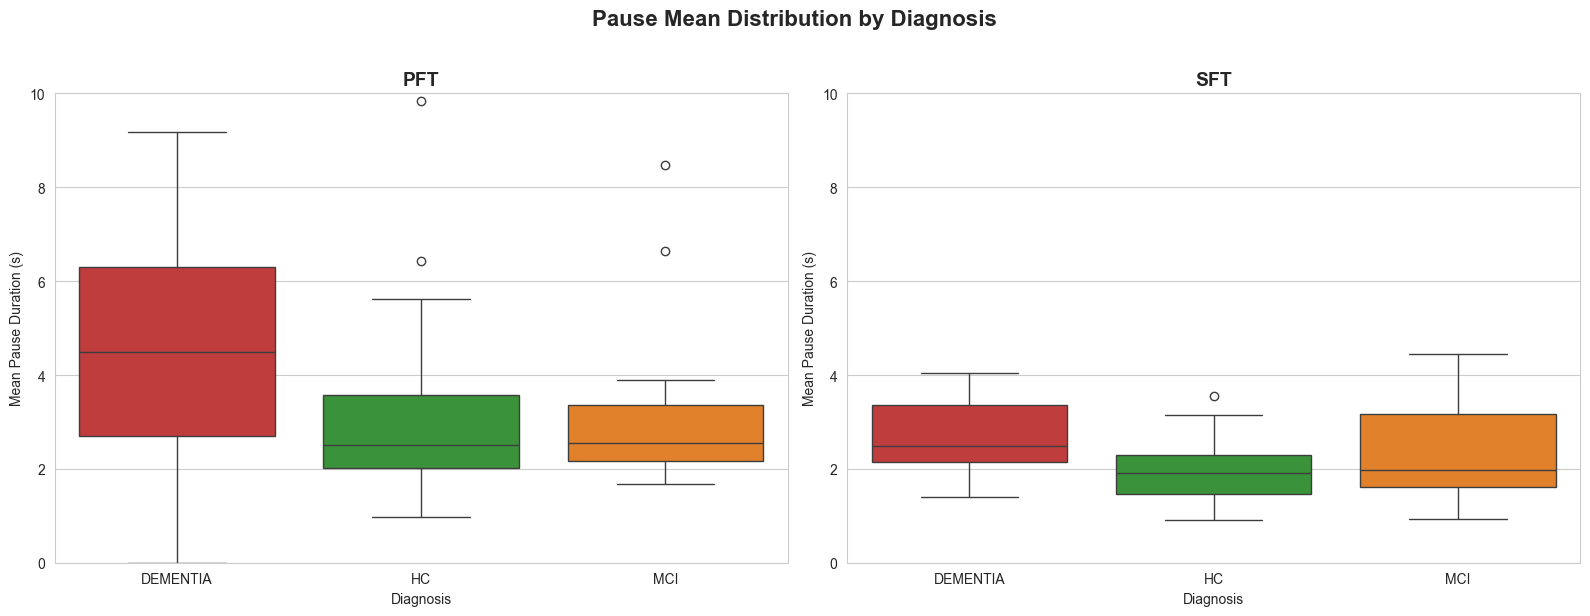


diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    19.0  4.635454  2.633455  2.707072  4.498602  6.309378
HC          39.0  3.057931  1.658557  2.024173  2.498866  3.567146
MCI         31.0  4.197133  7.086618  2.169523  2.555044  3.368917

diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    19.0  2.760843  0.813943  2.149098  2.497262  3.357538
HC          39.0  1.902879  0.656572  1.459291  1.902099  2.292626
MCI         30.0  2.308267  1.034430  1.616069  1.983833  3.160348


In [250]:
import re
from plotting import plot_3class_comparison, print_descriptive_stats

# Convert diagnosis to categorical with desired order
pause_with_diag['diagnosis'] = pd.Categorical(
    pause_with_diag['diagnosis'],
    categories=['DEMENTIA', 'HC', 'MCI'],
    ordered=True
)

# Extract task (PFT/SFT) from transcript path
pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_3class_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'diagnosis')
print_descriptive_stats(sft_data, 'diagnosis')


## Statistical Tests: 3-Class Comparison

Two-tailed independent samples t-tests to compare means between diagnosis groups.


TWO-TAILED T-TESTS: PFT

DEMENTIA vs HC:
  t-statistic: 2.7861
  p-value: 0.0073
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 0.2580
  p-value: 0.7975
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 0.9726
  p-value: 0.3342
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

DEMENTIA vs HC:
  t-statistic: 4.3134
  p-value: 0.0001
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 1.6146
  p-value: 0.1131
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 1.9844
  p-value: 0.0513
  Significant (p < 0.05): No 


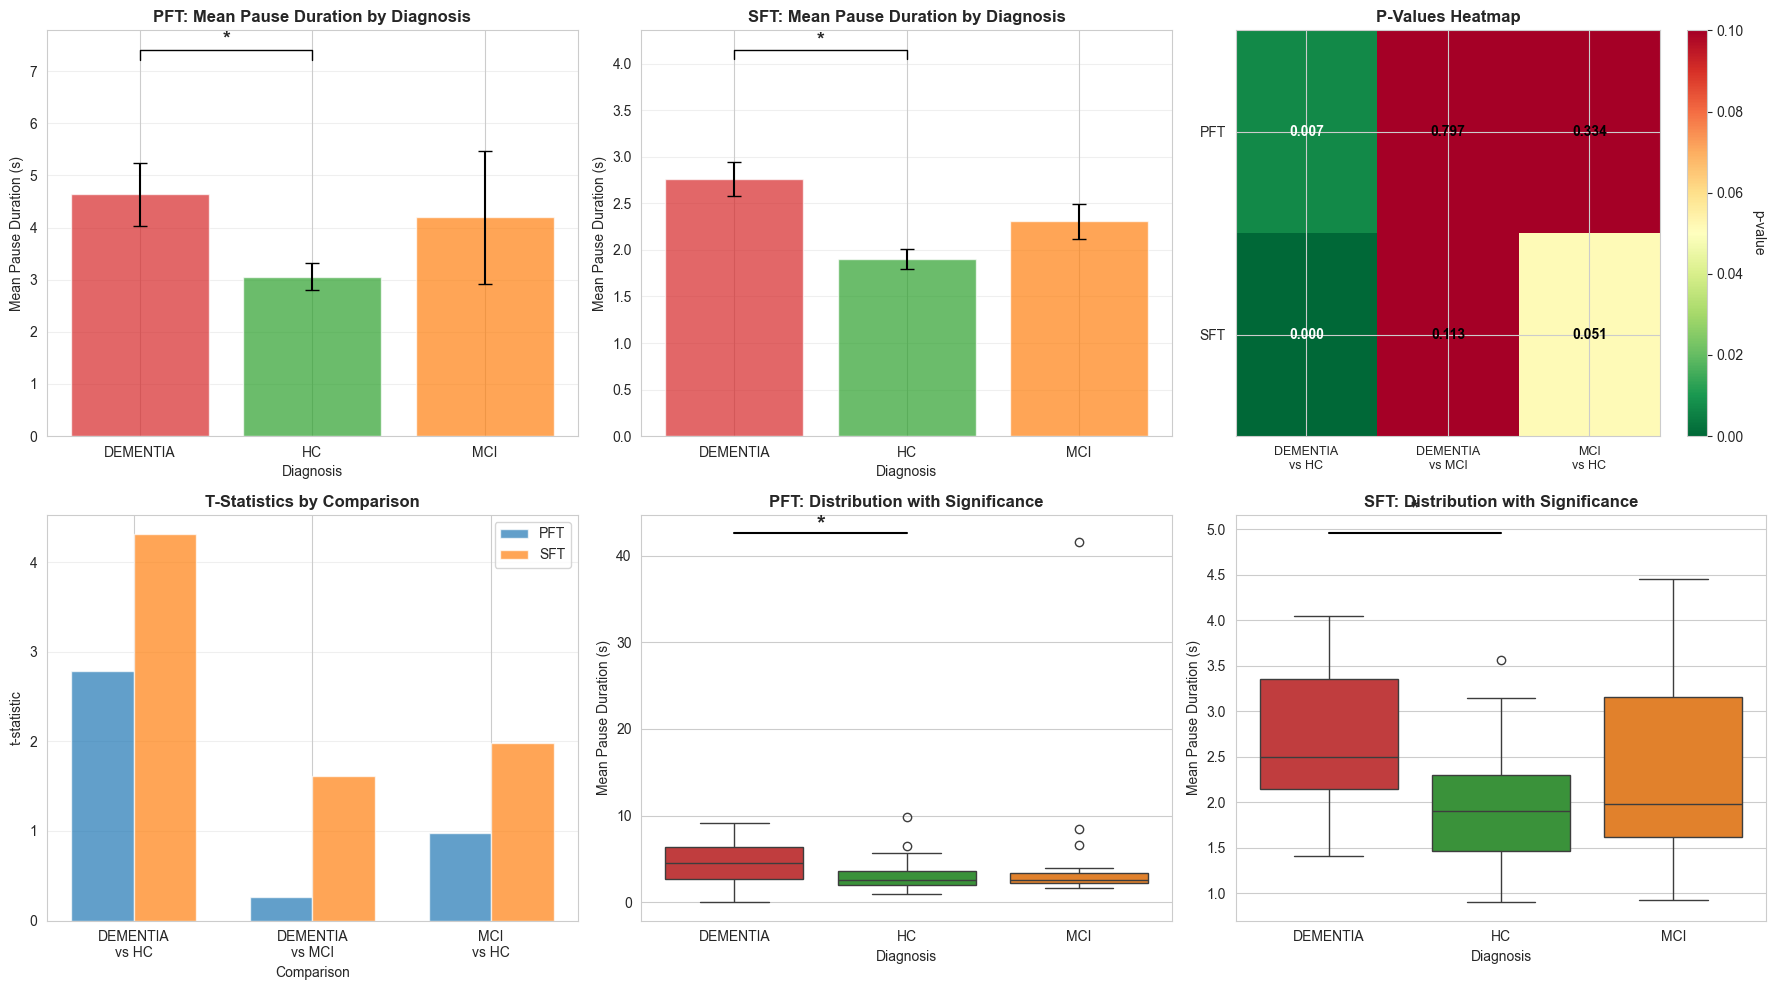


SUMMARY: Significant differences (p < 0.05) are marked with *


In [251]:
from statistical_tests import perform_3class_ttests, print_ttest_results, plot_3class_statistics

# Perform t-tests
test_results = perform_3class_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_3class_statistics(pft_data, sft_data, test_results)


## Healthy vs Non-Healthy by Task (PFT and SFT)

Compare Healthy vs Non-Healthy groups separately for PFT and SFT tasks.


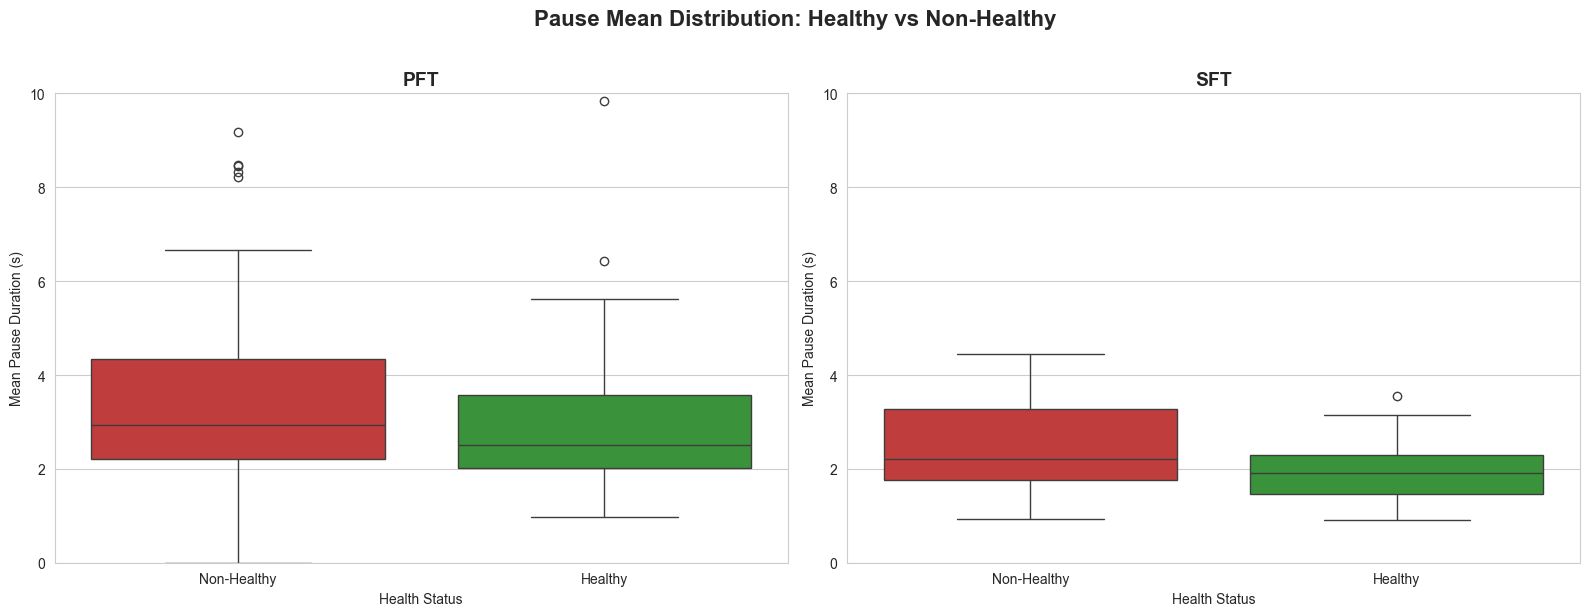


health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     50.0  4.363695  5.774150  2.213693  2.934726  4.349339
Healthy         39.0  3.057931  1.658557  2.024173  2.498866  3.567146

health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     49.0  2.483756  0.971886  1.772560  2.208759  3.273116
Healthy         39.0  1.902879  0.656572  1.459291  1.902099  2.292626


In [252]:
import re
from plotting import plot_binary_comparison, print_descriptive_stats

# Extract task (PFT/SFT) from transcript path (if not already done)
if 'task' not in pause_with_diag.columns:
    pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Create health_status if not already created
if 'health_status' not in pause_with_diag_filtered.columns:
    pause_with_diag_filtered['health_status'] = pause_with_diag_filtered['diagnosis'].apply(
        lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
    )
    pause_with_diag_filtered['health_status'] = pd.Categorical(
        pause_with_diag_filtered['health_status'],
        categories=['Non-Healthy', 'Healthy'],
        ordered=True
    )

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_binary_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'health_status')
print_descriptive_stats(sft_data, 'health_status')


## Statistical Tests: Binary Comparison (Healthy vs Non-Healthy)

Two-tailed independent samples t-tests to compare means between Healthy and Non-Healthy groups.


TWO-TAILED T-TESTS: PFT

Healthy vs Non-Healthy:
  t-statistic: -1.3674
  p-value: 0.1750
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

Healthy vs Non-Healthy:
  t-statistic: -3.1953
  p-value: 0.0020
  Significant (p < 0.05): Yes *


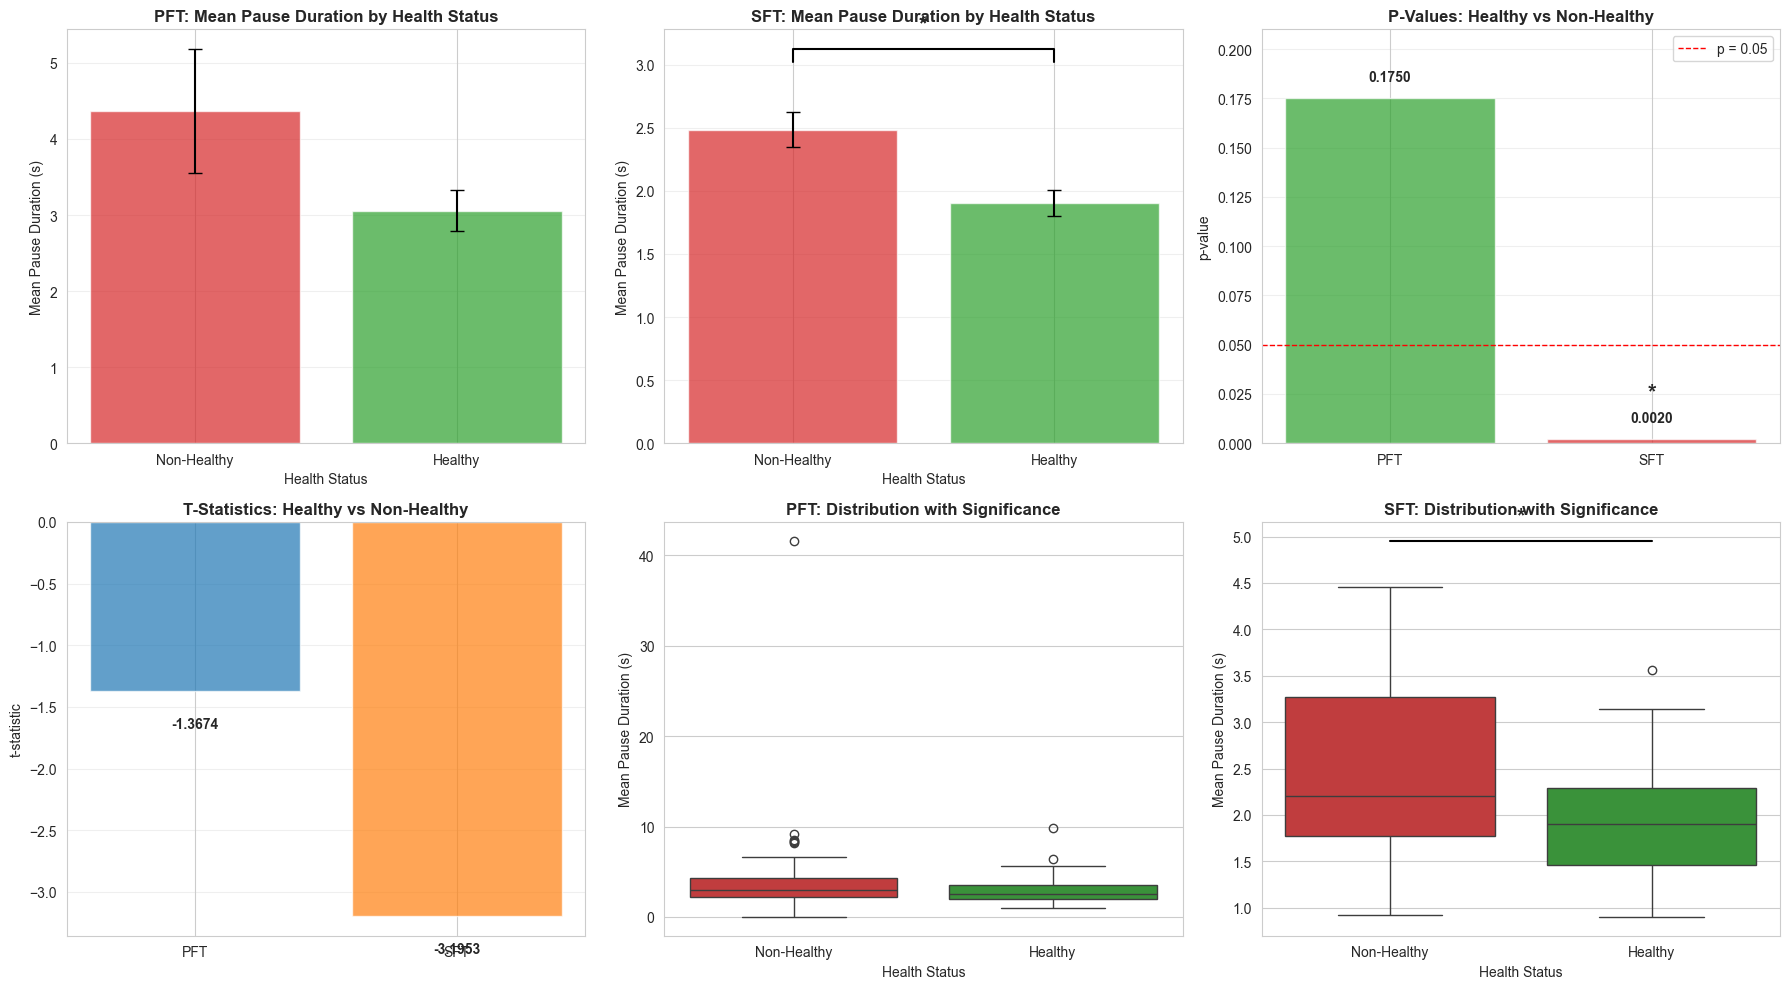


SUMMARY: Significant differences (p < 0.05) are marked with *


In [253]:
from statistical_tests import perform_binary_ttests, print_ttest_results, plot_binary_statistics

# Perform t-tests
test_results = perform_binary_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_binary_statistics(pft_data, sft_data, test_results)


## Statistical Tests with Demographic Covariates (ANCOVA)

Repeat the significance tests controlling for age and gender using ANCOVA (Analysis of Covariance). This allows us to test whether differences remain significant after accounting for demographic factors.


In [254]:
# Merge demographic data (age and gender) with pause data
pause_with_diag_demo = pause_summary.merge(
    metadata.rename(columns={'anyon_IDs': 'recording'})[['recording', 'diagnosis', 'age', 'gender']],
    on='recording',
    how='left'
)
pause_with_diag_demo.dropna(subset=['diagnosis'], inplace=True)

# Extract task (PFT/SFT) from transcript path
pause_with_diag_demo['task'] = pause_with_diag_demo['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_demo_filtered = pause_with_diag_demo[pause_with_diag_demo['task'].isin(['PFT', 'SFT'])].copy()

# Convert diagnosis to categorical with desired order
pause_with_diag_demo_filtered['diagnosis'] = pd.Categorical(
    pause_with_diag_demo_filtered['diagnosis'],
    categories=['DEMENTIA', 'HC', 'MCI'],
    ordered=True
)

# Create health_status
pause_with_diag_demo_filtered['health_status'] = pause_with_diag_demo_filtered['diagnosis'].apply(
    lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
)
pause_with_diag_demo_filtered['health_status'] = pd.Categorical(
    pause_with_diag_demo_filtered['health_status'],
    categories=['Non-Healthy', 'Healthy'],
    ordered=True
)

# Prepare data
pft_data_demo = pause_with_diag_demo_filtered[pause_with_diag_demo_filtered['task'] == 'PFT']
sft_data_demo = pause_with_diag_demo_filtered[pause_with_diag_demo_filtered['task'] == 'SFT']

print(f"PFT data with demographics: {len(pft_data_demo)} samples")
print(f"SFT data with demographics: {len(sft_data_demo)} samples")
print(f"\nMissing age values - PFT: {pft_data_demo['age'].isna().sum()}, SFT: {sft_data_demo['age'].isna().sum()}")
print(f"Missing gender values - PFT: {pft_data_demo['gender'].isna().sum()}, SFT: {sft_data_demo['gender'].isna().sum()}")


PFT data with demographics: 89 samples
SFT data with demographics: 88 samples

Missing age values - PFT: 0, SFT: 0
Missing gender values - PFT: 0, SFT: 0


### 3-Class Comparison with Demographics (ANCOVA)


In [255]:
from statistical_tests import perform_3class_ancova, perform_3class_ttests, print_ttest_results

# Perform ANCOVA tests controlling for age and gender
test_results_demo = perform_3class_ancova(pft_data_demo, sft_data_demo)

# Print results
print("="*80)
print("ANCOVA TESTS (controlling for age and gender): 3-CLASS COMPARISON")
print("="*80)
print_ttest_results(test_results_demo)

# Regenerate original 3-class t-test results for comparison
# (test_results may have been overwritten with binary results in a later cell)
test_results_3class = perform_3class_ttests(pft_data, sft_data)

# Compare with original t-test results
print("\n" + "="*80)
print("COMPARISON: Original t-tests vs ANCOVA (with demographics)")
print("="*80)

comparisons = ['DEMENTIA vs HC', 'DEMENTIA vs MCI', 'MCI vs HC']
for task in ['PFT', 'SFT']:
    print(f"\n{task}:")
    for comp in comparisons:
        orig_p = test_results_3class[task][comp]['p_value']
        demo_p = test_results_demo[task][comp]['p_value']
        orig_sig = test_results_3class[task][comp]['significant']
        demo_sig = test_results_demo[task][comp]['significant']
        
        change = ""
        if not orig_sig and demo_sig:
            change = " → NOW SIGNIFICANT!"
        elif orig_sig and not demo_sig:
            change = " → NO LONGER SIGNIFICANT"
        
        print(f"  {comp}:")
        print(f"    Original p-value: {orig_p:.4f} {'*' if orig_sig else ''}")
        print(f"    ANCOVA p-value:   {demo_p:.4f} {'*' if demo_sig else ''}{change}")


ANCOVA TESTS (controlling for age and gender): 3-CLASS COMPARISON
TWO-TAILED T-TESTS: PFT

DEMENTIA vs HC:
  f-statistic: 11.1981
  p-value: 0.0015
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  f-statistic: 0.1008
  p-value: 0.7523
  Significant (p < 0.05): No 

MCI vs HC:
  f-statistic: 0.9353
  p-value: 0.3370
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

DEMENTIA vs HC:
  f-statistic: 16.6963
  p-value: 0.0001
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  f-statistic: 2.8050
  p-value: 0.1008
  Significant (p < 0.05): No 

MCI vs HC:
  f-statistic: 4.0354
  p-value: 0.0486
  Significant (p < 0.05): Yes *

COMPARISON: Original t-tests vs ANCOVA (with demographics)

PFT:
  DEMENTIA vs HC:
    Original p-value: 0.0073 *
    ANCOVA p-value:   0.0015 *
  DEMENTIA vs MCI:
    Original p-value: 0.7975 
    ANCOVA p-value:   0.7523 
  MCI vs HC:
    Original p-value: 0.3342 
    ANCOVA p-value:   0.3370 

SFT:
  DEMENTIA vs HC:
    Original p-value: 0.0001 *
    ANCOVA 

/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1894: ValueWarning:

### Binary Comparison with Demographics (ANCOVA)


In [256]:
from statistical_tests import perform_binary_ancova

# Perform ANCOVA tests controlling for age and gender
binary_test_results_demo = perform_binary_ancova(pft_data_demo, sft_data_demo)

# Print results
print("="*80)
print("ANCOVA TESTS (controlling for age and gender): BINARY COMPARISON")
print("="*80)
print_ttest_results(binary_test_results_demo)

# Compare with original t-test results (from Cell 18)
print("\n" + "="*80)
print("COMPARISON: Original t-tests vs ANCOVA (with demographics)")
print("="*80)

# Get original binary test results from earlier cell
from statistical_tests import perform_binary_ttests
binary_test_results_orig = perform_binary_ttests(pft_data_orig, sft_data_orig)

for task in ['PFT', 'SFT']:
    orig_p = binary_test_results_orig[task]['Healthy vs Non-Healthy']['p_value']
    demo_p = binary_test_results_demo[task]['Healthy vs Non-Healthy']['p_value']
    orig_sig = binary_test_results_orig[task]['Healthy vs Non-Healthy']['significant']
    demo_sig = binary_test_results_demo[task]['Healthy vs Non-Healthy']['significant']
    
    change = ""
    if not orig_sig and demo_sig:
        change = " → NOW SIGNIFICANT!"
    elif orig_sig and not demo_sig:
        change = " → NO LONGER SIGNIFICANT"
    
    print(f"\n{task}:")
    print(f"  Original p-value: {orig_p:.4f} {'*' if orig_sig else ''}")
    print(f"  ANCOVA p-value:   {demo_p:.4f} {'*' if demo_sig else ''}{change}")


ANCOVA TESTS (controlling for age and gender): BINARY COMPARISON
TWO-TAILED T-TESTS: PFT

Healthy vs Non-Healthy:
  f-statistic: 2.0059
  p-value: 0.1603
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

Healthy vs Non-Healthy:
  f-statistic: 10.1020
  p-value: 0.0021
  Significant (p < 0.05): Yes *

COMPARISON: Original t-tests vs ANCOVA (with demographics)

PFT:
  Original p-value: 0.2026 
  ANCOVA p-value:   0.1603 

SFT:
  Original p-value: 0.0015 *
  ANCOVA p-value:   0.0021 *


/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/Users/bentindal/Desktop/CognoSpeak/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J


## Binary Classifier: Dementia vs Healthy

Build a binary classifier using SFT pause metrics to distinguish Dementia (1) from Healthy (0). We'll use 5-fold cross-validation and visualize the results with a confusion matrix.


In [257]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report

from binary_classifier import build_feature_dataset, get_classifier

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 8)


In [258]:
# Build feature dataset using SFT pause metrics only
features_df = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df)} recordings")
print(f"  - Dementia: {sum(features_df['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df['label'] == 0)}")

# Prepare features and labels
feature_cols = [col for col in features_df.columns if col.startswith('sft_')]
X = features_df[feature_cols].fillna(0)
y = features_df['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 58 recordings
  - Dementia: 19
  - Healthy (HC): 39

Using 12 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3
  - sft_repeated_words_count
  - sft_repeated_words_std


In [259]:
# Perform 5-fold cross-validation and collect predictions for confusion matrix
k_folds = 5
cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=24)
classifier = get_classifier('logistic')

# Store all predictions and true labels across folds
all_y_true = []
all_y_pred = []
fold_accuracies = []

print(f"Running {k_folds}-fold cross-validation...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Train and predict
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    
    # Store predictions
    all_y_true.extend(y_test.values)
    all_y_pred.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies.append(fold_acc)
    
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")


Running 5-fold cross-validation...

Fold 1: Accuracy = 0.9167
Fold 2: Accuracy = 0.6667
Fold 3: Accuracy = 0.6667
Fold 4: Accuracy = 0.7273
Fold 5: Accuracy = 0.7273

Mean accuracy across 5 folds: 0.7409 ± 0.0920


In [260]:
# Generate confusion matrix
cm = confusion_matrix(all_y_true, all_y_pred)

# Print classification report
print("Classification Report (aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true, all_y_pred, 
                          target_names=['Healthy (HC)', 'Dementia']))
print("=" * 60)


Classification Report (aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.80      0.82      0.81        39
    Dementia       0.61      0.58      0.59        19

    accuracy                           0.74        58
   macro avg       0.71      0.70      0.70        58
weighted avg       0.74      0.74      0.74        58



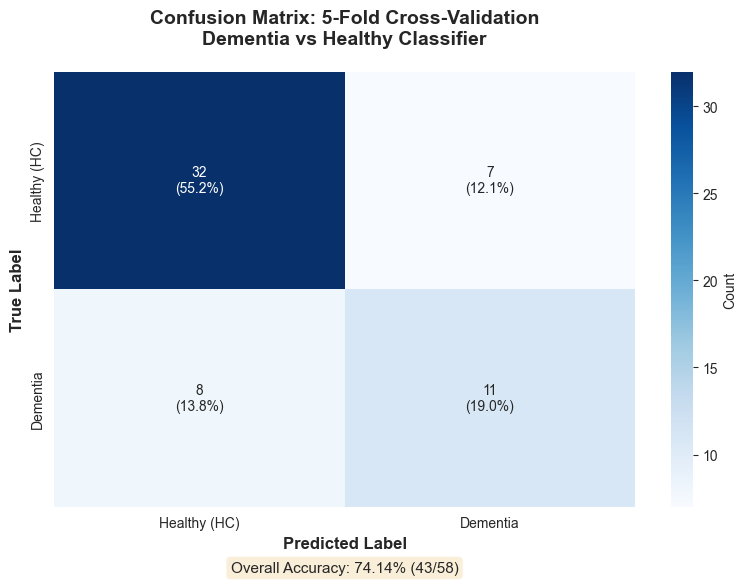

In [261]:
# Plot confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate percentages of total sample
total_samples = cm.sum()
cm_percent_total = cm.astype('float') / total_samples * 100

# Create annotation labels with both count and percentage of total
annot_labels = []
for i in range(len(cm)):
    row = []
    for j in range(len(cm)):
        count = cm[i, j]
        percent = cm_percent_total[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap with custom annotations
sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', 
            xticklabels=['Healthy (HC)', 'Dementia'],
            yticklabels=['Healthy (HC)', 'Dementia'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nDementia vs Healthy Classifier', 
             fontsize=14, fontweight='bold', pad=20)

# Add accuracy text
total = cm.sum()
correct = np.trace(cm)
accuracy = correct / total
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()


## Binary Classifier with Demographics: Age and Gender Features

Compare the binary classifier performance when including participant age and gender as additional features. This experiment tests whether demographic information improves the accuracy of distinguishing Dementia from Healthy controls.


In [262]:
# Build feature dataset with demographics (age and gender)
features_df_demo = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False,  # Use SFT only
    include_demographics=True  # Include age and gender
)

print(f"Loaded {len(features_df_demo)} recordings")
print(f"  - Dementia: {sum(features_df_demo['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df_demo['label'] == 0)}")

# Prepare features and labels (including demographics)
feature_cols_demo = [col for col in features_df_demo.columns 
                    if col.startswith('sft_') or col == 'age' or col == 'gender_encoded']
X_demo = features_df_demo[feature_cols_demo].fillna(0)
y_demo = features_df_demo['label']

# Handle missing age values with median
if 'age' in X_demo.columns:
    age_median = X_demo['age'].median()
    if pd.notna(age_median):
        X_demo['age'] = X_demo['age'].fillna(age_median)
    else:
        X_demo['age'] = X_demo['age'].fillna(0)

print(f"\nUsing {len(feature_cols_demo)} features (including demographics):")
for col in feature_cols_demo:
    print(f"  - {col}")


Loaded 58 recordings
  - Dementia: 19
  - Healthy (HC): 39

Using 14 features (including demographics):
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3
  - sft_repeated_words_count
  - sft_repeated_words_std
  - age
  - gender_encoded


In [263]:
# Perform 5-fold cross-validation with demographics and collect predictions
k_folds = 5
cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=24)
classifier_demo = get_classifier('logistic')

# Store all predictions and true labels across folds
all_y_true_demo = []
all_y_pred_demo = []
fold_accuracies_demo = []

print(f"Running {k_folds}-fold cross-validation with demographics...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_demo, y_demo), 1):
    X_train, X_test = X_demo.iloc[train_idx], X_demo.iloc[test_idx]
    y_train, y_test = y_demo.iloc[train_idx], y_demo.iloc[test_idx]
    
    # Train and predict
    classifier_demo.fit(X_train, y_train)
    y_pred = classifier_demo.predict(X_test)
    
    # Store predictions
    all_y_true_demo.extend(y_test.values)
    all_y_pred_demo.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies_demo.append(fold_acc)
    
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies_demo):.4f} ± {np.std(fold_accuracies_demo):.4f}")

# Compare with baseline (without demographics)
print(f"\nComparison:")
print(f"  Baseline (without demographics): {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")
print(f"  With demographics:              {np.mean(fold_accuracies_demo):.4f} ± {np.std(fold_accuracies_demo):.4f}")
improvement = np.mean(fold_accuracies_demo) - np.mean(fold_accuracies)
print(f"  Improvement:                    {improvement:+.4f} ({improvement*100:+.2f}%)")


Running 5-fold cross-validation with demographics...

Fold 1: Accuracy = 0.9167
Fold 2: Accuracy = 0.6667
Fold 3: Accuracy = 0.5833
Fold 4: Accuracy = 0.7273
Fold 5: Accuracy = 0.5455

Mean accuracy across 5 folds: 0.6879 ± 0.1308

Comparison:
  Baseline (without demographics): 0.7409 ± 0.0920
  With demographics:              0.6879 ± 0.1308
  Improvement:                    -0.0530 (-5.30%)


## Multiclass Classifier: Dementia vs MCI vs HC

Build a multiclass classifier using SFT pause metrics to distinguish all three classes: Healthy (HC), Mild Cognitive Impairment (MCI), and Dementia. This is an exploratory model to see how well we can distinguish all three groups.


In [264]:
# Generate confusion matrix for model with demographics
cm_demo = confusion_matrix(all_y_true_demo, all_y_pred_demo)

# Print classification report
print("Classification Report (with demographics, aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true_demo, all_y_pred_demo, 
                          target_names=['Healthy (HC)', 'Dementia']))
print("=" * 60)


Classification Report (with demographics, aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.77      0.77      0.77        39
    Dementia       0.53      0.53      0.53        19

    accuracy                           0.69        58
   macro avg       0.65      0.65      0.65        58
weighted avg       0.69      0.69      0.69        58



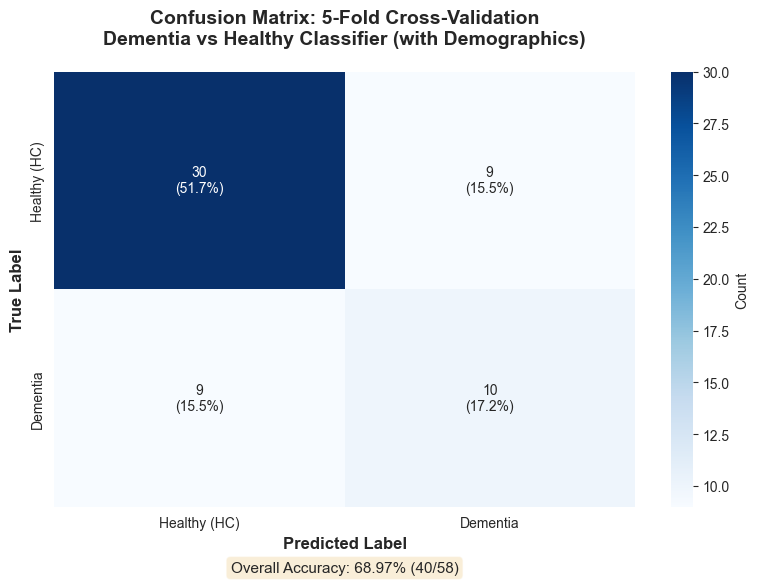

In [265]:
# Plot confusion matrix for model with demographics
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate percentages of total sample
total_samples_demo = cm_demo.sum()
cm_percent_total_demo = cm_demo.astype('float') / total_samples_demo * 100

# Create annotation labels with both count and percentage of total
annot_labels_demo = []
for i in range(len(cm_demo)):
    row = []
    for j in range(len(cm_demo)):
        count = cm_demo[i, j]
        percent = cm_percent_total_demo[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels_demo.append(row)

# Create heatmap with custom annotations
sns.heatmap(cm_demo, annot=annot_labels_demo, fmt='', cmap='Blues', 
            xticklabels=['Healthy (HC)', 'Dementia'],
            yticklabels=['Healthy (HC)', 'Dementia'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nDementia vs Healthy Classifier (with Demographics)', 
             fontsize=14, fontweight='bold', pad=20)

# Add accuracy text
total_demo = cm_demo.sum()
correct_demo = np.trace(cm_demo)
accuracy_demo = correct_demo / total_demo
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy_demo*100:.2f}% ({correct_demo}/{total_demo})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()


In [266]:
from multiclass_classifier import build_feature_dataset, get_classifier, evaluate_with_cv, print_cv_results, plot_confusion_matrix

# Build feature dataset for multiclass classification (includes MCI)
features_df_multiclass = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df_multiclass)} recordings")
print("\nClass distribution:")
for label_val, count in features_df_multiclass['label'].value_counts().sort_index().items():
    diagnosis_name = features_df_multiclass[features_df_multiclass['label'] == label_val]['diagnosis'].iloc[0]
    print(f"  {diagnosis_name}: {count}")

# Prepare features and labels
feature_cols = [col for col in features_df_multiclass.columns if col.startswith('sft_')]
X_multiclass = features_df_multiclass[feature_cols].fillna(0)
y_multiclass = features_df_multiclass['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 88 recordings

Class distribution:
  HC: 39
  MCI: 30
  DEMENTIA: 19

Using 10 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3


In [267]:
# Perform 5-fold cross-validation for multiclass classification
k_folds = 5
classifier_multiclass = get_classifier('random_forest')  # Random Forest works well for multiclass

print(f"Performing {k_folds}-fold cross-validation for multiclass classification...")
cv_results_multiclass = evaluate_with_cv(X_multiclass, y_multiclass, classifier_multiclass, k_folds=k_folds)

# Display CV results as a pandas DataFrame
cv_results_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Mean': [
        cv_results_multiclass['accuracy_mean'],
        cv_results_multiclass['precision_mean'],
        cv_results_multiclass['recall_mean'],
        cv_results_multiclass['f1_mean']
    ],
    'Std': [
        cv_results_multiclass['accuracy_std'],
        cv_results_multiclass['precision_std'],
        cv_results_multiclass['recall_std'],
        cv_results_multiclass['f1_std']
    ]
})
cv_results_df['Mean ± Std'] = cv_results_df.apply(
    lambda row: f"{row['Mean']:.4f} ± {row['Std']:.4f}", axis=1
)
cv_results_df = cv_results_df[['Metric', 'Mean ± Std']]

print("\n" + "=" * 80)
print("K-FOLD CROSS-VALIDATION RESULTS (Multiclass: HC vs MCI vs Dementia)")
print("=" * 80)
display(cv_results_df)
print("=" * 80 + "\n")


Performing 5-fold cross-validation for multiclass classification...

K-FOLD CROSS-VALIDATION RESULTS (Multiclass: HC vs MCI vs Dementia)


,Metric,Mean ± Std
0,Accuracy,0.5680 ± 0.0778
1,Precision (Macro),0.5521 ± 0.1071
2,Recall (Macro),0.5421 ± 0.0767
3,F1-Score (Macro),0.5352 ± 0.0842


In [268]:
# Collect predictions across all folds for confusion matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)
all_y_true_multiclass = []
all_y_pred_multiclass = []

print(f"Running {k_folds}-fold cross-validation to collect predictions...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_multiclass, y_multiclass), 1):
    X_train, X_test = X_multiclass.iloc[train_idx], X_multiclass.iloc[test_idx]
    y_train, y_test = y_multiclass.iloc[train_idx], y_multiclass.iloc[test_idx]
    
    # Train and predict
    classifier_multiclass.fit(X_train, y_train)
    y_pred = classifier_multiclass.predict(X_test)
    
    # Store predictions
    all_y_true_multiclass.extend(y_test.values)
    all_y_pred_multiclass.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean([(np.array(all_y_pred_multiclass)[i::k_folds] == np.array(all_y_true_multiclass)[i::k_folds]).mean() for i in range(k_folds)]):.4f}")


Running 5-fold cross-validation to collect predictions...

Fold 1: Accuracy = 0.6667
Fold 2: Accuracy = 0.5556
Fold 3: Accuracy = 0.5000
Fold 4: Accuracy = 0.6471
Fold 5: Accuracy = 0.4706

Mean accuracy across 5 folds: 0.5693


In [269]:
# Create detailed classification report as pandas DataFrame

# Calculate per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    all_y_true_multiclass,
    all_y_pred_multiclass,
    labels=[0, 1, 2],
    zero_division=0
)

# Create DataFrame
class_names = ['HC', 'MCI', 'Dementia']
classification_results_df = pd.DataFrame({
    'Class': class_names,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

# Format for display
classification_results_df['Precision'] = classification_results_df['Precision'].apply(lambda x: f'{x:.4f}')
classification_results_df['Recall'] = classification_results_df['Recall'].apply(lambda x: f'{x:.4f}')
classification_results_df['F1-Score'] = classification_results_df['F1-Score'].apply(lambda x: f'{x:.4f}')

print("\n" + "=" * 80)
print("DETAILED CLASSIFICATION REPORT (Per-Class Metrics)")
print("=" * 80)
display(classification_results_df)

# Calculate overall accuracy
overall_accuracy = accuracy_score(all_y_true_multiclass, all_y_pred_multiclass)
print(f"\nOverall Accuracy: {overall_accuracy:.4f} ({overall_accuracy*100:.2f}%)")
print(f"Total Samples: {len(all_y_true_multiclass)}")
print("=" * 80 + "\n")



DETAILED CLASSIFICATION REPORT (Per-Class Metrics)


,Class,Precision,Recall,F1-Score,Support
0,HC,0.6000,0.6923,0.6429,39
1,MCI,0.5000,0.5000,0.5000,30
2,Dementia,0.6154,0.4211,0.5000,19



Overall Accuracy: 0.5682 (56.82%)
Total Samples: 88



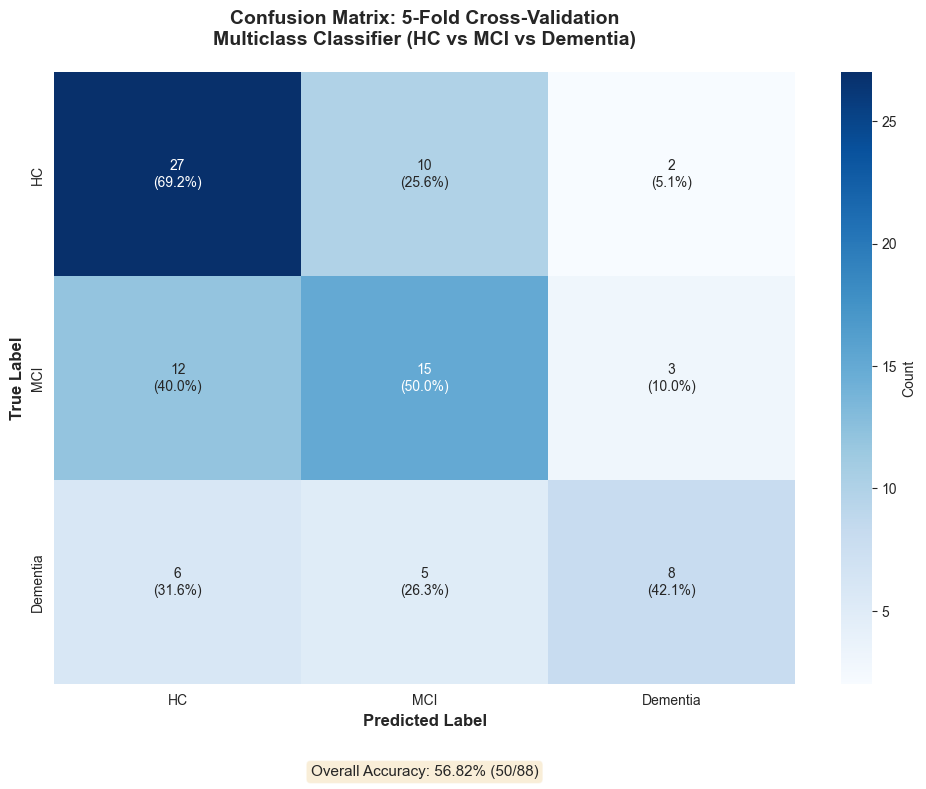

In [270]:
# Plot confusion matrix for multiclass classification
cm_multiclass = confusion_matrix(all_y_true_multiclass, all_y_pred_multiclass)

fig, ax = plt.subplots(figsize=(10, 8))

# Calculate percentages of each row (true class)
# This ensures each row sums to exactly 100%
row_sums = cm_multiclass.sum(axis=1)
# Avoid division by zero (shouldn't happen, but safety check)
row_sums = np.where(row_sums == 0, 1, row_sums)

# Calculate percentages and normalize to ensure each row sums to exactly 100%
cm_percent = np.zeros_like(cm_multiclass, dtype=float)
for i in range(len(cm_multiclass)):
    if row_sums[i] > 0:
        # Calculate percentages for this row
        cm_percent[i, :] = cm_multiclass[i, :].astype('float') / row_sums[i] * 100
        # Ensure it sums to exactly 100% by normalizing
        row_total = cm_percent[i, :].sum()
        if row_total > 0:
            cm_percent[i, :] = cm_percent[i, :] / row_total * 100

# Create annotation labels with both count and percentage
annot_labels = []
class_names = ['HC', 'MCI', 'Dementia']
for i in range(len(cm_multiclass)):
    row = []
    for j in range(len(cm_multiclass)):
        count = cm_multiclass[i, j]
        percent = cm_percent[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap
sns.heatmap(
    cm_multiclass, 
    annot=annot_labels, 
    fmt='', 
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'},
    ax=ax
)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title(
    'Confusion Matrix: 5-Fold Cross-Validation\nMulticlass Classifier (HC vs MCI vs Dementia)',
    fontsize=14,
    fontweight='bold',
    pad=20
)

# Add accuracy text
total = cm_multiclass.sum()
correct = np.trace(cm_multiclass)
accuracy = correct / total
ax.text(
    0.5, -0.15,
    f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
    transform=ax.transAxes,
    ha='center',
    fontsize=11,
    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
)

plt.tight_layout()
plt.show()


In [271]:
# Display confusion matrix as pandas DataFrame
cm_df = pd.DataFrame(
    cm_multiclass,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

# Add row totals
cm_df['Total'] = cm_df.sum(axis=1)

# Calculate percentages for each row
cm_percent_df = pd.DataFrame(
    cm_percent,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Counts)")
print("=" * 80)
display(cm_df)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Percentages - each row sums to 100%)")
print("=" * 80)
# Format percentages
cm_percent_df_formatted = cm_percent_df.applymap(lambda x: f'{x:.1f}%')
display(cm_percent_df_formatted)
print("=" * 80 + "\n")



CONFUSION MATRIX (Counts)


,Pred: HC,Pred: MCI,Pred: Dementia,Total
True: HC,27,10,2,39
True: MCI,12,15,3,30
True: Dementia,6,5,8,19



CONFUSION MATRIX (Percentages - each row sums to 100%)


/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_54128/3657399134.py:27: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cm_percent_df_formatted = cm_percent_df.applymap(lambda x: f'{x:.1f}%')


,Pred: HC,Pred: MCI,Pred: Dementia
True: HC,69.2%,25.6%,5.1%
True: MCI,40.0%,50.0%,10.0%
True: Dementia,31.6%,26.3%,42.1%


## Multiclass Classifier with Demographics: Age and Gender Features

Compare the multiclass classifier performance when including participant age and gender as additional features. This experiment tests whether demographic information improves the accuracy of distinguishing all three classes: Healthy (HC), Mild Cognitive Impairment (MCI), and Dementia.


In [272]:
# Reload the module to get the updated function with include_demographics parameter
import importlib
import multiclass_classifier
importlib.reload(multiclass_classifier)
from multiclass_classifier import build_feature_dataset, get_classifier, evaluate_with_cv, print_cv_results, plot_confusion_matrix

# Build feature dataset for multiclass classification with demographics
features_df_multiclass_demo = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False,  # Use SFT only
    include_demographics=True  # Include age and gender
)

print(f"Loaded {len(features_df_multiclass_demo)} recordings")
print("\nClass distribution:")
for label_val, count in features_df_multiclass_demo['label'].value_counts().sort_index().items():
    diagnosis_name = features_df_multiclass_demo[features_df_multiclass_demo['label'] == label_val]['diagnosis'].iloc[0]
    print(f"  {diagnosis_name}: {count}")

# Prepare features and labels (including demographics)
feature_cols_demo_multiclass = [col for col in features_df_multiclass_demo.columns 
                               if col.startswith('sft_') or col == 'age' or col == 'gender_encoded']
X_multiclass_demo = features_df_multiclass_demo[feature_cols_demo_multiclass].fillna(0)
y_multiclass_demo = features_df_multiclass_demo['label']

# Handle missing age values with median
if 'age' in X_multiclass_demo.columns:
    age_median = X_multiclass_demo['age'].median()
    if pd.notna(age_median):
        X_multiclass_demo['age'] = X_multiclass_demo['age'].fillna(age_median)
    else:
        X_multiclass_demo['age'] = X_multiclass_demo['age'].fillna(0)

print(f"\nUsing {len(feature_cols_demo_multiclass)} features (including demographics):")
for col in feature_cols_demo_multiclass:
    print(f"  - {col}")


Loaded 88 recordings

Class distribution:
  HC: 39
  MCI: 30
  DEMENTIA: 19

Using 12 features (including demographics):
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total
  - sft_pause_q1
  - sft_pause_q2
  - sft_pause_q3
  - age
  - gender_encoded


In [273]:
# Perform 5-fold cross-validation for multiclass classification with demographics
k_folds = 5
classifier_multiclass_demo = get_classifier('random_forest')  # Random Forest works well for multiclass

print(f"Performing {k_folds}-fold cross-validation for multiclass classification with demographics...")
cv_results_multiclass_demo = evaluate_with_cv(X_multiclass_demo, y_multiclass_demo, classifier_multiclass_demo, k_folds=k_folds)

# Display CV results as a pandas DataFrame
cv_results_df_demo = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Mean': [
        cv_results_multiclass_demo['accuracy_mean'],
        cv_results_multiclass_demo['precision_mean'],
        cv_results_multiclass_demo['recall_mean'],
        cv_results_multiclass_demo['f1_mean']
    ],
    'Std': [
        cv_results_multiclass_demo['accuracy_std'],
        cv_results_multiclass_demo['precision_std'],
        cv_results_multiclass_demo['recall_std'],
        cv_results_multiclass_demo['f1_std']
    ]
})
cv_results_df_demo['Mean ± Std'] = cv_results_df_demo.apply(
    lambda row: f"{row['Mean']:.4f} ± {row['Std']:.4f}", axis=1
)
cv_results_df_demo = cv_results_df_demo[['Metric', 'Mean ± Std']]

print("\n" + "=" * 80)
print("K-FOLD CROSS-VALIDATION RESULTS (Multiclass with Demographics: HC vs MCI vs Dementia)")
print("=" * 80)
display(cv_results_df_demo)

# Compare with baseline
print("\n" + "=" * 80)
print("COMPARISON: Baseline vs With Demographics")
print("=" * 80)
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Baseline': [
        cv_results_multiclass['accuracy_mean'],
        cv_results_multiclass['precision_mean'],
        cv_results_multiclass['recall_mean'],
        cv_results_multiclass['f1_mean']
    ],
    'With Demographics': [
        cv_results_multiclass_demo['accuracy_mean'],
        cv_results_multiclass_demo['precision_mean'],
        cv_results_multiclass_demo['recall_mean'],
        cv_results_multiclass_demo['f1_mean']
    ]
})
# Calculate improvement before formatting
improvement_values = comparison_df['With Demographics'] - comparison_df['Baseline']
comparison_df['Improvement'] = improvement_values.apply(lambda x: f'{x:+.4f} ({x*100:+.2f}%)')
comparison_df['Baseline'] = comparison_df['Baseline'].apply(lambda x: f'{x:.4f}')
comparison_df['With Demographics'] = comparison_df['With Demographics'].apply(lambda x: f'{x:.4f}')
display(comparison_df)
print("=" * 80 + "\n")


Performing 5-fold cross-validation for multiclass classification with demographics...

K-FOLD CROSS-VALIDATION RESULTS (Multiclass with Demographics: HC vs MCI vs Dementia)


,Metric,Mean ± Std
0,Accuracy,0.5124 ± 0.0683
1,Precision (Macro),0.5401 ± 0.0359
2,Recall (Macro),0.4837 ± 0.0704
3,F1-Score (Macro),0.4854 ± 0.0628



COMPARISON: Baseline vs With Demographics


,Metric,Baseline,With Demographics,Improvement
0,Accuracy,0.5680,0.5124,-0.0556 (-5.56%)
1,Precision (Macro),0.5521,0.5401,-0.0119 (-1.19%)
2,Recall (Macro),0.5421,0.4837,-0.0583 (-5.83%)
3,F1-Score (Macro),0.5352,0.4854,-0.0499 (-4.99%)


In [274]:
# Collect predictions across all folds for confusion matrix with demographics
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)
all_y_true_multiclass_demo = []
all_y_pred_multiclass_demo = []

print(f"Running {k_folds}-fold cross-validation to collect predictions (with demographics)...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_multiclass_demo, y_multiclass_demo), 1):
    X_train, X_test = X_multiclass_demo.iloc[train_idx], X_multiclass_demo.iloc[test_idx]
    y_train, y_test = y_multiclass_demo.iloc[train_idx], y_multiclass_demo.iloc[test_idx]
    
    # Train and predict
    classifier_multiclass_demo.fit(X_train, y_train)
    y_pred = classifier_multiclass_demo.predict(X_test)
    
    # Store predictions
    all_y_true_multiclass_demo.extend(y_test.values)
    all_y_pred_multiclass_demo.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean([(np.array(all_y_pred_multiclass_demo)[i::k_folds] == np.array(all_y_true_multiclass_demo)[i::k_folds]).mean() for i in range(k_folds)]):.4f}")


Running 5-fold cross-validation to collect predictions (with demographics)...

Fold 1: Accuracy = 0.5000
Fold 2: Accuracy = 0.5556
Fold 3: Accuracy = 0.3889
Fold 4: Accuracy = 0.5882
Fold 5: Accuracy = 0.5294

Mean accuracy across 5 folds: 0.5124


In [275]:
# Create detailed classification report as pandas DataFrame (with demographics)

# Calculate per-class metrics
precision_demo, recall_demo, f1_demo, support_demo = precision_recall_fscore_support(
    all_y_true_multiclass_demo,
    all_y_pred_multiclass_demo,
    labels=[0, 1, 2],
    zero_division=0
)

# Create DataFrame
class_names = ['HC', 'MCI', 'Dementia']
classification_results_df_demo = pd.DataFrame({
    'Class': class_names,
    'Precision': precision_demo,
    'Recall': recall_demo,
    'F1-Score': f1_demo,
    'Support': support_demo
})

# Format for display
classification_results_df_demo['Precision'] = classification_results_df_demo['Precision'].apply(lambda x: f'{x:.4f}')
classification_results_df_demo['Recall'] = classification_results_df_demo['Recall'].apply(lambda x: f'{x:.4f}')
classification_results_df_demo['F1-Score'] = classification_results_df_demo['F1-Score'].apply(lambda x: f'{x:.4f}')

print("\n" + "=" * 80)
print("DETAILED CLASSIFICATION REPORT (Per-Class Metrics) - WITH DEMOGRAPHICS")
print("=" * 80)
display(classification_results_df_demo)

# Calculate overall accuracy
overall_accuracy_demo = accuracy_score(all_y_true_multiclass_demo, all_y_pred_multiclass_demo)
print(f"\nOverall Accuracy: {overall_accuracy_demo:.4f} ({overall_accuracy_demo*100:.2f}%)")
print(f"Total Samples: {len(all_y_true_multiclass_demo)}")
print("=" * 80 + "\n")



DETAILED CLASSIFICATION REPORT (Per-Class Metrics) - WITH DEMOGRAPHICS


,Class,Precision,Recall,F1-Score,Support
0,HC,0.5417,0.6667,0.5977,39
1,MCI,0.4138,0.4000,0.4068,30
2,Dementia,0.6364,0.3684,0.4667,19



Overall Accuracy: 0.5114 (51.14%)
Total Samples: 88



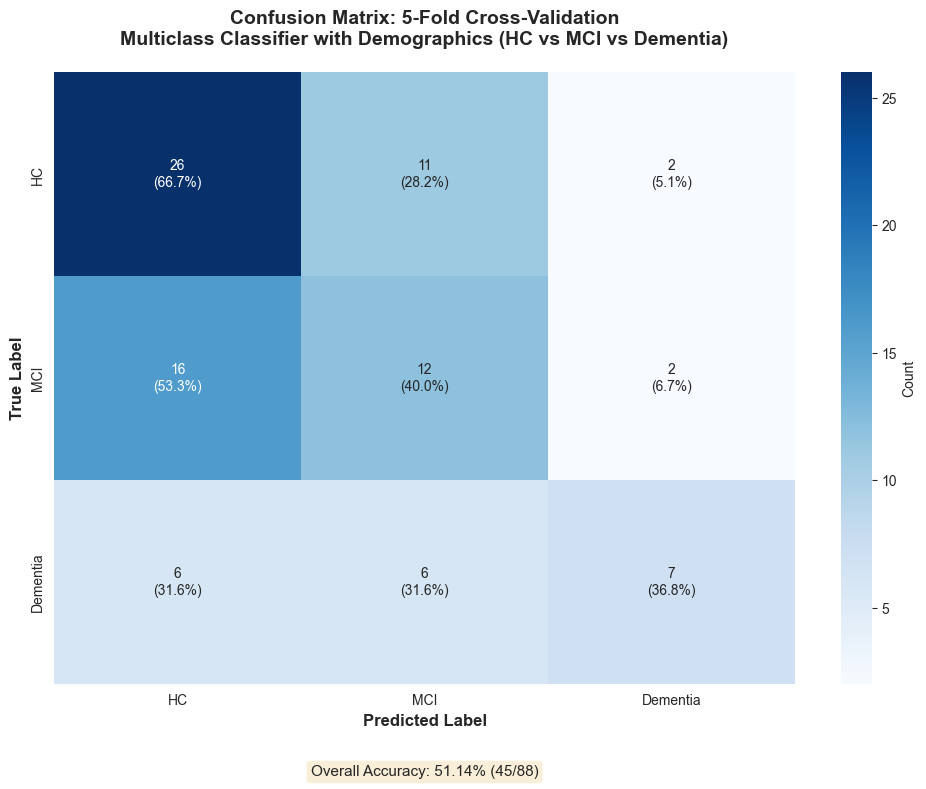

In [276]:
# Plot confusion matrix for multiclass classification with demographics
cm_multiclass_demo = confusion_matrix(all_y_true_multiclass_demo, all_y_pred_multiclass_demo)

fig, ax = plt.subplots(figsize=(10, 8))

# Calculate percentages of each row (true class)
# This ensures each row sums to exactly 100%
row_sums_demo = cm_multiclass_demo.sum(axis=1)
# Avoid division by zero (shouldn't happen, but safety check)
row_sums_demo = np.where(row_sums_demo == 0, 1, row_sums_demo)

# Calculate percentages and normalize to ensure each row sums to exactly 100%
cm_percent_demo = np.zeros_like(cm_multiclass_demo, dtype=float)
for i in range(len(cm_multiclass_demo)):
    if row_sums_demo[i] > 0:
        # Calculate percentages for this row
        cm_percent_demo[i, :] = cm_multiclass_demo[i, :].astype('float') / row_sums_demo[i] * 100
        # Ensure it sums to exactly 100% by normalizing
        row_total = cm_percent_demo[i, :].sum()
        if row_total > 0:
            cm_percent_demo[i, :] = cm_percent_demo[i, :] / row_total * 100

# Create annotation labels with both count and percentage
annot_labels_demo = []
class_names = ['HC', 'MCI', 'Dementia']
for i in range(len(cm_multiclass_demo)):
    row = []
    for j in range(len(cm_multiclass_demo)):
        count = cm_multiclass_demo[i, j]
        percent = cm_percent_demo[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels_demo.append(row)

# Create heatmap
sns.heatmap(
    cm_multiclass_demo, 
    annot=annot_labels_demo, 
    fmt='', 
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'},
    ax=ax
)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title(
    'Confusion Matrix: 5-Fold Cross-Validation\nMulticlass Classifier with Demographics (HC vs MCI vs Dementia)',
    fontsize=14,
    fontweight='bold',
    pad=20
)

# Add accuracy text
total_demo = cm_multiclass_demo.sum()
correct_demo = np.trace(cm_multiclass_demo)
accuracy_demo = correct_demo / total_demo
ax.text(
    0.5, -0.15,
    f'Overall Accuracy: {accuracy_demo*100:.2f}% ({correct_demo}/{total_demo})',
    transform=ax.transAxes,
    ha='center',
    fontsize=11,
    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
)

plt.tight_layout()
plt.show()


In [277]:
# Display confusion matrix as pandas DataFrame (with demographics)
cm_df_demo = pd.DataFrame(
    cm_multiclass_demo,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

# Add row totals
cm_df_demo['Total'] = cm_df_demo.sum(axis=1)

# Calculate percentages for each row
cm_percent_df_demo = pd.DataFrame(
    cm_percent_demo,
    index=['True: HC', 'True: MCI', 'True: Dementia'],
    columns=['Pred: HC', 'Pred: MCI', 'Pred: Dementia']
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Counts) - WITH DEMOGRAPHICS")
print("=" * 80)
display(cm_df_demo)

print("\n" + "=" * 80)
print("CONFUSION MATRIX (Percentages - each row sums to 100%) - WITH DEMOGRAPHICS")
print("=" * 80)
# Format percentages
cm_percent_df_formatted_demo = cm_percent_df_demo.map(lambda x: f'{x:.1f}%')
display(cm_percent_df_formatted_demo)
print("=" * 80 + "\n")



CONFUSION MATRIX (Counts) - WITH DEMOGRAPHICS


,Pred: HC,Pred: MCI,Pred: Dementia,Total
True: HC,26,11,2,39
True: MCI,16,12,2,30
True: Dementia,6,6,7,19



CONFUSION MATRIX (Percentages - each row sums to 100%) - WITH DEMOGRAPHICS


,Pred: HC,Pred: MCI,Pred: Dementia
True: HC,66.7%,28.2%,5.1%
True: MCI,53.3%,40.0%,6.7%
True: Dementia,31.6%,31.6%,36.8%
